<a href="https://colab.research.google.com/github/sevval-sarici/dsa107-lab/blob/main/Lab03_Groups_and_two_quantitative_variables_Starter_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DSA 107 — Lab 3: Groups, and two quantitative variables

**Week 3 · w/c 12 October 2026** · paired with DSA 101 lecture week 3

**Name:** Şevval Sarıcı   **Student ID:** 25221021010

---

### What you will produce

A runnable Colab notebook, pushed to your `dsa107-labs` repository. In it you count and filter rows with boolean masks, summarise one variable group by group, measure how two quantitative variables move together, draw two labelled figures, and read a box plot.

### Before you start

Run the setup cell below. If any import fails, run
`!pip install pandas matplotlib seaborn` in a new cell and try again.

### How to use this notebook

Every code cell has a **Goal** written just above it. Read the goal, then write the code. You do not need to open the handout while you work — everything you have to do is in this notebook.

Every Goal and every question shows how many **points** it is worth. The table below shows how they add up to the 10 code points.

A code cell only shows the result of its **last line**. If you want to see two or more things from one cell, put each of them inside `print()`.

The **Command reference** below holds the commands you need for this lab, and a few more besides. Read it once now, and come back to it whenever you are stuck.

### How the 10 code points are shared

| Part | Where in this notebook | Points |
| --- | --- | --- |
| Setup and data loading | Goals 1a, 1b (0.5 each) | 1 |
| Boolean masks and filtering | Goals 2a, 2b (0.75 each) | 1.5 |
| Group summaries | Goals 3a, 3b (1 each) | 2 |
| Correlation | Goal 4b | 1 |
| Figures | Goals 4a, 4c (0.5 each — every figure needs an x label, a y label and a title) | 1 |
| Interpretation | Q1, Q2 (0.5 each) · Q3, Q4 (0.75 each) | 2.5 |
| Reading a box plot | Q5a, Q5b (0.5 each) | 1 |
| **Total** | | **10** |

In [42]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")
print("pandas", pd.__version__)

pandas 2.2.3


## Command reference

`df` means a whole table (a DataFrame). `s` means a single column (a Series).
Not every command here is needed for this lab — choosing the right one is part of the work.

**Looking at the table**

| Command | What it does |
| --- | --- |
| `pd.read_csv(url)` | reads a CSV file, from a web address or from your computer |
| `df.head(n)` | returns the first `n` rows (5 if you do not say) |
| `df.tail(n)` | returns the last `n` rows |
| `df.shape` | gives (number of rows, number of columns) |
| `len(df)` | gives the number of rows |
| `df.info()` | prints the column names, their types and their non-missing counts |
| `df.describe()` | prints count, mean, std, min, quartiles and max for the numeric columns |

**Missing values, and sorting**

| Command | What it does |
| --- | --- |
| `df.isna().sum()` | gives the number of missing values in each column |
| `s.sort_values()` | sorts from smallest to largest |
| `s.sort_values(ascending=False)` | sorts from largest to smallest |
| `s.value_counts()` | counts how many times each value appears |

**Boolean masks — new this week**

A *boolean mask* is a column of `True` / `False` values, one for every row.

| Command | What it does |
| --- | --- |
| `df["col"] == "usa"` | for every row: is the value equal to `"usa"`? (text needs quotes) |
| `df["col"] != "usa"` | for every row: is the value **not** equal to `"usa"`? |
| `df["col"] > 30` | for every row: is the value bigger than 30? You can also use `>=`, `<`, `<=` |
| `mask.sum()` | how many rows are `True` (True counts as 1, False as 0) |
| `mask.mean()` | what **fraction** of the rows are `True` |
| `df[mask]` | keeps only the rows where the mask is `True` |
| `df[(mask1) & (mask2)]` | keeps rows where **both** are `True` — each condition needs its own brackets |
| `df[(mask1) \| (mask2)]` | keeps rows where **at least one** is `True` |

**Group summaries — new this week**

| Command | What it does |
| --- | --- |
| `df.groupby("g")["x"].mean()` | splits the rows into groups by `g`, then gives the mean of `x` in each group |
| `.median()` `.count()` `.max()` `.min()` `.std()` | put one of these in place of `.mean()` for another summary |
| `df.groupby(["g1", "g2"])["x"].mean()` | one group for every **combination** of `g1` and `g2` |
| `.unstack()` | turns a two-key result into a grid: `g1` down the side, `g2` across the top |

**Numbers**

| Command | What it does |
| --- | --- |
| `s.mean()` / `s.median()` / `s.std()` | mean / median / standard deviation of one column |
| `s.min()` / `s.max()` | the smallest / the largest value |
| `round(x, 2)` | rounds one number to 2 decimal places |
| `s.round(2)` / `table.round(2)` | rounds every value of a column or a table |

**Two quantitative columns**

| Command | What it does |
| --- | --- |
| `df[["a", "b", "c"]]` | picks out several columns — note the **double** brackets |
| `df[["a", "b"]].corr()` | the correlation of every pair of columns, as a table |
| `table.loc["a", "b"]` | picks out one cell, by its row name and its column name (names in quotes) |

**Drawing and labelling**

The plot commands hand you back an *axes* object. Catch it in a variable (`ax = ...`) and you can label it.

| Command | What it does |
| --- | --- |
| `ax = s.plot.bar()` | draws a bar chart, one bar per row |
| `ax = s.plot.barh()` | the same, with horizontal bars |
| `ax = s.plot.hist(bins=20)` | draws a histogram with 20 bins |
| `ax = df.plot.scatter(x="a", y="b")` | draws a scatter plot: one dot per row |
| `ax = sns.scatterplot(data=df, x="a", y="b", hue="g")` | a scatter plot with the dots **coloured** by the groups in `g` |
| `alpha=0.5` | add inside a plot command: makes the dots see-through, so overlaps show |
| `sns.boxplot(data=df, x="g", y="x")` | a box plot, one box per group (used in the ready-made cell in Part 5) |
| `ax.set_xlabel("...")` | names the horizontal axis |
| `ax.set_ylabel("...")` | names the vertical axis |
| `ax.set_title("...")` | puts a title on the figure |
| `ax.legend(title="...")` | names the legend |
| `plt.show()` | shows the finished figure |

A figure in this course is not finished until it has both axis labels and a title.

## 1. Load the data and look at it

This week's dataset is **Auto MPG**: 398 car models sold in the United States between 1970 and 1982.
It is **not** one of the lecture datasets (flights and penguins). That is on purpose: the method carries over, the answers do not.

| Column | What it means |
| --- | --- |
| `mpg` | miles per gallon: how far the car goes on one gallon of fuel. **Higher is better** — the car uses less fuel |
| `cylinders` | number of cylinders in the engine. More cylinders usually means a bigger engine |
| `displacement` | the size of the engine (cubic inches) |
| `horsepower` | the power of the engine |
| `weight` | the weight of the car in pounds (1 pound ≈ 0.45 kg) |
| `acceleration` | seconds needed to go from 0 to 60 miles per hour. **Higher means slower** |
| `model_year` | the year of the model: 70 means 1970 |
| `origin` | where the car was made: `usa`, `europe` or `japan` |
| `name` | the name of the car |

> **Goal 1a · 0.5 pt.** Load the CSV into a DataFrame called `cars` (this line is already written for you). Print the shape of the table, then show its first five rows.

In [43]:
cars = pd.read_csv("https://raw.githubusercontent.com/mwaskom/seaborn-data/master/mpg.csv")

# TODO: print the shape, then show the first five rows
print(cars.shape)
cars.info()
cars.head(5)

(398, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    object 
 8   name          398 non-null    object 
dtypes: float64(4), int64(3), object(2)
memory usage: 28.1+ KB


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


> **Goal 1b · 0.5 pt.** Count the missing values in each column, and show the worst column first.

In [44]:
# TODO: count the missing values per column, sorted from most to fewest
print(cars.isna().sum().sort_values(ascending=False))

horsepower      6
mpg             0
cylinders       0
displacement    0
weight          0
acceleration    0
model_year      0
origin          0
name            0
dtype: int64


**Q1 · 0.5 pt.** How many rows and how many columns are there, and what does one row represent?
Which column has missing values, and how many?
Would you still use that column in an analysis? Say why in one sentence.

There are 398 rows, 9 columns.  One row represents features of each car.

Horsepower has missing values and it is 6.

I can use it. Because there are still many rows which has valuable datas.



## 2. Boolean masks: asking a yes / no question of every row

Type `cars["mpg"] >= 30` and you do **not** get one `True` or `False`. You get one answer for **every row** — 398 of them. A column of `True` / `False` values like this is called a **boolean mask**.

- **Count.** `True` counts as 1 and `False` as 0, so `mask.sum()` is the number of rows where the answer is yes.
- **Find a fraction.** `mask.mean()` is the number of yes rows divided by all rows.
- **Filter.** `cars[mask]` keeps the rows where the mask is `True` and drops the rest.

> **Goal 2a · 0.75 pt.** Make a boolean mask that is `True` for every car with an `mpg` of **30 or more**, and store it as `high_mpg`. Then print **how many** cars have an `mpg` of 30 or more, and **what fraction** of all cars that is, rounded to 3 decimal places.

In [45]:
# TODO: build the mask, then print the count (.sum()) and the fraction (.mean())
high_mpg = cars["mpg"] >= 30
count = high_mpg.sum()
fraction = high_mpg.mean()

print("Count:", count)
print("Fraction:", round(fraction, 3))

Count: 92
Fraction: 0.231


> **Goal 2b · 0.75 pt.** Keep only the cars made in Japan (from the original `cars` dataframe) and store them in a DataFrame called `japan`. Print the number of rows in `cars` and the number of rows in `japan`.

In [46]:
# TODO: filter to the Japanese cars, then print the row count cars and japan
japan = cars[cars["origin"] == "japan"]

print("Total cars:", len(cars))
print("Japanese cars:", len(japan))

Total cars: 398
Japanese cars: 79


**Q2 · 0.5 pt.** How many cars have an `mpg` of 30 or more, and what fraction of all cars is that?
How many cars made in Japan?

92 cars have an mpg of 30 or more. The fraction iss 0.231

There are 79 cars made in Japan.

## 3. Split, apply, combine with `groupby`

`groupby` compares groups in one line, in three steps: **split** the rows into groups, **apply** the same summary to every group, and **combine** the answers into one table.

Before you believe a group mean, always ask two questions: **How big is the group?** and **What else is different between the groups?**

> **Goal 3a · 1 pt.** Find the **mean** `mpg` for each `origin`, rounded to 2 decimal places, and store it as `mean_mpg`. Then find the **number of cars** in each `origin` with `.count()`, and store it as `n_cars`. Print both.
> **Check:** print the sum of `n_cars` next to `len(cars)`. They must be equal.

In [47]:
# TODO: mean mpg per origin (mean_mpg), number of cars per origin (n_cars), and the check
mean_mpg = cars.groupby("origin")["mpg"].mean().round(2)
n_cars = cars.groupby("origin")["mpg"].count()

print("Mean MPG per origin:")
print(mean_mpg)
print("\nNumber of cars per origin:")
print(n_cars)
print("\nCheck:", n_cars.sum() == len(cars), f"(Sum: {n_cars.sum()}, Total: {len(cars)})")

Mean MPG per origin:
origin
europe    27.89
japan     30.45
usa       20.08
Name: mpg, dtype: float64

Number of cars per origin:
origin
europe     70
japan      79
usa       249
Name: mpg, dtype: int64

Check: True (Sum: 398, Total: 398)


I used gemini ai for goal 3a.

print("Mean MPG per origin:")

print(mean_mpg)

print("\nNumber of cars per origin:")

print(n_cars)

print("\nCheck:", n_cars.sum() == len(cars), f"(Sum: {n_cars.sum()}, Total: {len(cars)})")


> **Goal 3b · 1 pt.** Group by **two** keys at once: `origin` and `cylinders`. Find the mean `mpg` of every combination, then use `.unstack()` so that `origin` runs down the side and `cylinders` runs across the top. Round to 1 decimal place, store it as `by_two`, and show it.
> An empty cell shows `NaN`. It means there are no cars in that combination.

In [48]:
# TODO: mean mpg for every origin and cylinders combination, as a grid, stored as by_two
by_two = cars.groupby(["origin", "cylinders"])["mpg"].mean().unstack().round(1)
print(by_two)

cylinders     3     4     5     6     8
origin                                 
europe      NaN  28.4  27.4  20.1   NaN
japan      20.6  31.6   NaN  23.9   NaN
usa         NaN  27.8   NaN  19.7  15.0


**Q3 · 0.75 pt.**
(a) Which origin has the highest mean `mpg`, and which has the lowest? How many cars are in each group?
(b) Look only at the **4-cylinder** column of `by_two`. How big is the gap between `japan` and `usa` there, and how big is it in `mean_mpg`? Which cylinder group has cars from the USA only?
(c) In one sentence: is "made in the USA" on its own the reason for the low mean `mpg`, or is another variable mixed in?

a) Highest one is Japan with 30.45 mpg. There are 79 cars in the group.

Lowest one is USA with 20.08 mpg. There are 249 cars in the group.

b)The gap is 3.8.

In mean_mpg the gap is 10.37.

8-cylinder has cars from the USA only.

c)The fact that US cars have low average MPG ratings is not solely due to where they are manufactured; it is also because the US vehicle fleet consists predominantly of high cylinder vehicles.

## 4. Two quantitative variables

A **scatter plot** shows one dot per row, with no summary at all. The **correlation coefficient** *r* puts one number on it:

- *r* is always between −1 and +1.
- **Negative** *r*: when x goes up, y tends to go down. **Positive** *r*: both go up together.
- The closer *r* is to −1 or +1, the closer the dots are to a straight line. Near 0 means **no straight-line** relationship.

> **Goal 4a · Figure · 0.5 pt.** Draw a scatter plot with `weight` on the x-axis and `mpg` on the y-axis. Give it an x label, a y label and a title. (All dataset must be plotted in one color only)

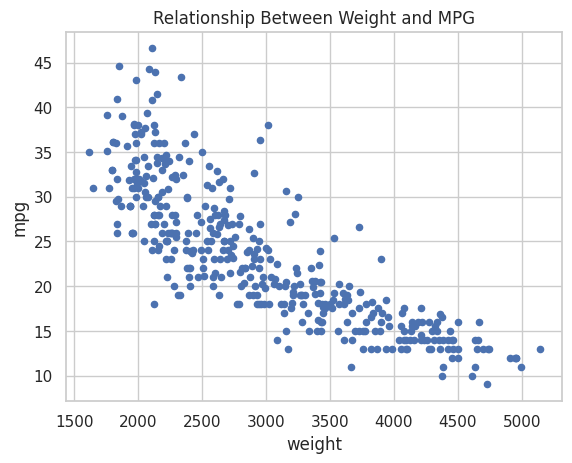

In [49]:
# TODO: labelled scatter plot of weight (x) against mpg (y)
ax = cars.plot.scatter(x="weight", y="mpg")
ax.set_title("Relationship Between Weight and MPG")
plt.show()

> **Goal 4b · 1 pt.** Make the correlation table of `mpg`, `weight` and `horsepower`, rounded to 2 decimal places, and store it as `corr_table`. Then use `.loc` to print the **one** number for `weight` and `mpg`.

In [53]:
# TODO: correlation table (corr_table), then print the weight-mpg value with .loc
corr_table = cars[["mpg", "weight", "horsepower"]].corr().round(2)
print(corr_table)
print(corr_table.loc["weight", "mpg"])

             mpg  weight  horsepower
mpg         1.00   -0.83       -0.78
weight     -0.83    1.00        0.86
horsepower -0.78    0.86        1.00
-0.83


> **Goal 4c · Figure · 0.5 pt.** Draw the same scatter plot again, but **colour the dots by `origin`** (use `sns.scatterplot` with `hue=`). Give it an x label, a y label and a title.

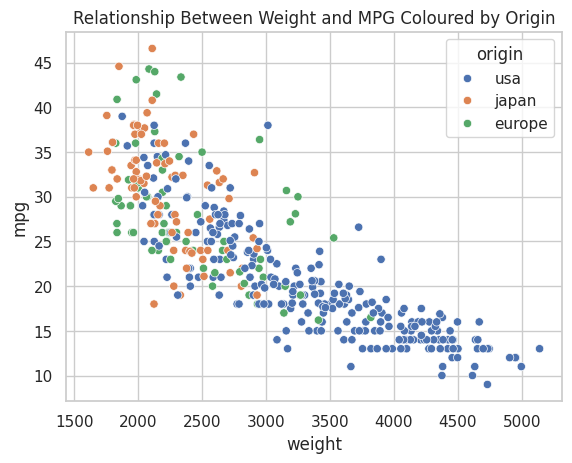

In [51]:
# TODO: labelled scatter plot of weight against mpg, coloured by origin
ax = sns.scatterplot(data=cars, x="weight", y="mpg", hue="origin")
ax.set_title("Relationship Between Weight and MPG")
ax.set_title("Relationship Between Weight and MPG Coloured by Origin")
ax.set_xlabel("weight")
ax.set_ylabel("mpg")

plt.show()

### Q4 · 0.75 pt.
(a) Describe the relationship between `weight` and `mpg` in one sentence: which direction does it go, and how strong is it? Use your *r* from Goal 4b.
(b) In the coloured plot, where do the cars from the USA sit compared with the cars from Japan and Europe?

a)There is a negative relationship between weight and MPG; as the weight of the vehicles increases, their MPG drops significantly.

b)In the graph, vehicles of US origin are generally located in the bottom-right section, whereas vehicles of Japanese and European origin are situated in the top-left section.

## 5. A new kind of figure: the box plot

Box plots were **not** covered in the lecture. You do **not** write any code in this part: run the ready-made cell, then read the figure with the help of the guide below.

```
      o      <- dot: an OUTLIER, a car far away from the other cars in its group
      |      <- top whisker: reaches up to the highest car that is not an outlier
   +-----+   <- top of the box: 75% of the cars in the group are below this line
   |-----|   <- line inside the box: the MEDIAN (half of the cars are below it, half above)
   +-----+   <- bottom of the box: 25% of the cars in the group are below this line
      |      <- bottom whisker: reaches down to the lowest car that is not an outlier
```

- The box holds the **middle half** of the cars in the group.
- The **height of the box** shows the **spread**. A tall box: the cars are very different from each other. A short box: they are similar.
- A box plot shows the **median**, not the mean.

> **Ready-made cell · 0 pt.** Do not change anything. Just run it.

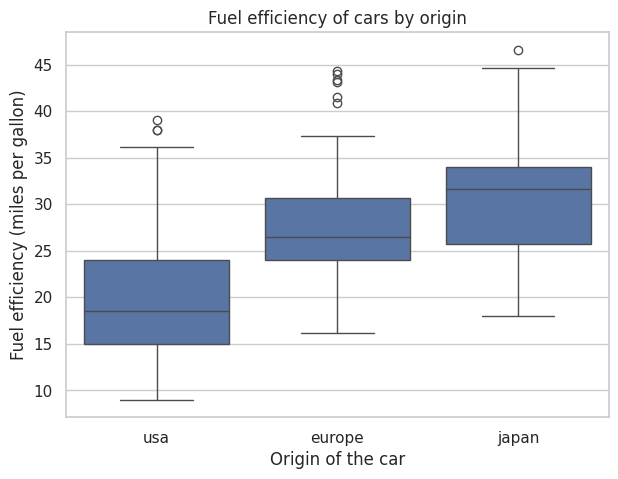

In [52]:
# Ready-made cell: you do not need to change anything. Just run it.
order = ["usa", "europe", "japan"]

fig, ax = plt.subplots(figsize=(7, 5))
sns.boxplot(data=cars, x="origin", y="mpg", order=order, ax=ax)
ax.set_xlabel("Origin of the car")
ax.set_ylabel("Fuel efficiency (miles per gallon)")
ax.set_title("Fuel efficiency of cars by origin")
plt.show()

**Q5a · 0.5 pt.** Which origin has the highest median `mpg`, and roughly what is it?
Which origin has the **shortest** box, and what does that tell you about the cars in that group?

Japan has the highest median value. It is about 31.6

USA has the shortest box, the fact that the box is short indicates that the fuel efficiency values of the vehicles in this group are quite close and similar to one another.

**Q5b · 0.5 pt.** Find the dots. Which origin has the most outliers, and are those cars unusually **high** or unusually **low** in `mpg`?
Look at the whiskers and the dots: is every Japanese car more fuel efficient than every US car? Name one thing the box plot shows that your (3a) `mean_mpg` table does not show.

Japan has the most outliers. These cars are unusually high  in mpg.

No, not every Japanese car is more fuel-efficient than every US car.

While the box plot displays the spread of the data, outliers and quartiles, the mean_mpg table presents only the mean.

## 6. Push to GitHub

1. You created a repository named `dsa107-labs` in Lab 1. Use the same one.
2. In Colab: **File → Save a copy in GitHub**, and choose that repository.
3. Paste the resulting link in the line below.

**Repository link:** _______________

---

## Submission checklist

- [ ] Every cell runs top to bottom without error (Runtime → Restart and run all)
- [ ] Both figures (Goals 4a and 4c) have an x label, a y label and a title
- [ ] All five written answers (Q1–Q5) are filled in — a figure with no reading of it scores zero on interpretation
- [ ] Notebook saved as `Lab03_Firstname_Lastname.ipynb`
- [ ] If you used an AI assistant, the log is attached as described in the course AI policy

Submit both files through MS Teams.